# Cat breed classifier
Train our own breed classifier and compare it with CLIP / ResNet. Plan: `CLASSIFIER_PLAN.md`.

## Step 1: data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

RAW = Path("../data/_raw/oxford-iiit-pet")
IMG_SIZE = 64
BATCH_SIZE = 32

### Split
Each annotation line is `name class_id species breed_id`; species 1 = cat.

We use the dataset's official split so our numbers are comparable to others, and because the 102 library images come from `trainval`: scoring on `test` keeps the comparison honest.

In [2]:
def read_split(name):
    rows = []
    for line in (RAW / "annotations" / name).read_text().splitlines():
        stem, _, species, _ = line.split()
        if species == "1":
            rows.append(stem)
    return rows


train_stems = read_split("trainval.txt")
test_stems = read_split("test.txt")

breeds = sorted({s.rsplit("_", 1)[0] for s in train_stems})
breed_to_idx = {b: i for i, b in enumerate(breeds)}

len(train_stems), len(test_stems), breeds

(1188,
 1183,
 ['Abyssinian',
  'Bengal',
  'Birman',
  'Bombay',
  'British_Shorthair',
  'Egyptian_Mau',
  'Maine_Coon',
  'Persian',
  'Ragdoll',
  'Russian_Blue',
  'Siamese',
  'Sphynx'])

### Dataset and DataLoader
- **`Dataset`**: knows *how to get one example*. It only needs `__len__` and `__getitem__`. Images are loaded lazily, so memory stays small.
- **`DataLoader`**: wraps a dataset and serves *batches*, shuffled for training. Shuffling stops the model from learning the order (all Abyssinians first, ...).
- **`transform`**: turns a PIL image into a tensor. Every image must have the same shape to stack into a batch, hence `Resize`.

In [3]:
class CatDataset(Dataset):
    def __init__(self, stems, transform):
        self.stems = stems
        self.transform = transform

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, i):
        stem = self.stems[i]
        image = Image.open(RAW / "images" / f"{stem}.jpg").convert("RGB")
        label = breed_to_idx[stem.rsplit("_", 1)[0]]
        return self.transform(image), label

In [4]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),  # PIL (H, W, C) 0-255 -> tensor (C, H, W) 0-1
])

train_ds = CatDataset(train_stems, transform)
test_ds = CatDataset(test_stems, transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

images, labels = next(iter(train_loader))
images.shape, labels.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

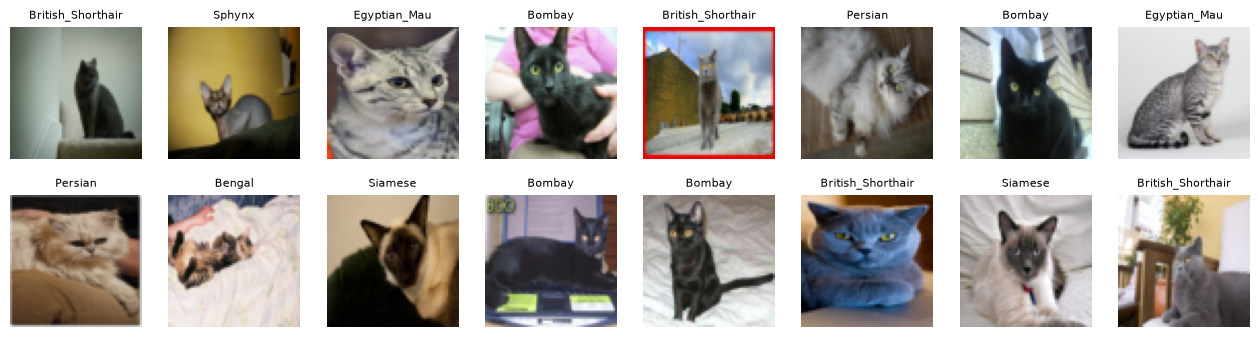

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, image, label in zip(axes.flat, images, labels):
    ax.imshow(image.permute(1, 2, 0))  # (C, H, W) -> (H, W, C) for matplotlib
    ax.set_title(breeds[label], fontsize=8)
    ax.axis("off")

## Step 2: tiny CNN from scratch

### Validation split
`test` is reserved for the final comparison. While training we need a third set to watch for overfitting and to tune choices against: **validation**, carved out of `trainval`. Tuning on `test` would make its score optimistic.

In [6]:
from torch.utils.data import random_split

torch.manual_seed(0)
train_part, val_part = random_split(train_ds, [0.8, 0.2])

train_loader = DataLoader(train_part, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_part, batch_size=BATCH_SIZE)

len(train_part), len(val_part)

(951, 237)

### The model
A CNN is a stack of small, learned filters:
- **`Conv2d`** slides 3×3 filters over the image. Early filters pick up edges and colours; deeper ones combine those into textures and shapes (fur pattern, ear shape).
- **`ReLU`** adds non-linearity. Without it, stacked layers collapse into one linear map.
- **`MaxPool2d(2)`** halves height and width: cheaper, and each later filter "sees" a larger part of the image.
- **`Linear`** at the end maps the features to **12 scores (logits)**, one per breed.

Shapes through the network, for one image:

| layer | output shape |
|---|---|
| input | 3 × 64 × 64 |
| conv(3→16) + relu + pool | 16 × 32 × 32 |
| conv(16→32) + relu + pool | 32 × 16 × 16 |
| conv(32→64) + relu + pool | 64 × 8 × 8 |
| flatten | 4096 |
| linear(4096→12) | 12 |

**Your turn:** fill in `TinyCNN`. Hints: `nn.Conv2d(in, out, kernel_size=3, padding=1)` keeps height/width the same; `nn.Sequential` chains layers; `nn.Flatten()` turns `64×8×8` into `4096`.

In [13]:
from torch import nn


class TinyCNN(nn.Module):
    def __init__(self, n_classes=len(breeds)):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(3, 16, kernel_size = 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(16, 32, kernel_size = 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2),
                                      nn.Conv2d(32, 64, kernel_size = 3, padding = 1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64*8*8, n_classes))

    def forward(self, x):
        x = self.features(x)
        return self.head(x)

Sanity check: one batch in, `[32, 12]` out. Checking shapes before training saves a lot of debugging.

In [14]:
model = TinyCNN()
n_params = sum(p.numel() for p in model.parameters())
model(images).shape, n_params

(torch.Size([32, 12]), 72748)

### Loss, optimizer, training loop
- **Loss: `CrossEntropyLoss`**. Softmax turns the 12 logits into probabilities; the loss is `-log(p of the correct breed)`. Confident and right → near 0; confident and wrong → large. Random guessing gives `log(12) ≈ 2.48`, a useful number to see at the start.
- **Optimizer: `Adam`**. Uses the gradients to nudge every weight. `lr` (learning rate) sets the step size.
- **One training step** is always the same 4 lines:
  1. `optimizer.zero_grad()`: clear old gradients (PyTorch adds them up by default)
  2. `loss = loss_fn(model(x), y)`: forward pass
  3. `loss.backward()`: compute gradients (backprop)
  4. `optimizer.step()`: update weights
- `model.train()` / `model.eval()` switch layers like dropout and batchnorm between modes (none yet, but a good habit). `torch.no_grad()` skips gradient bookkeeping during evaluation.

In [15]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

### Train
An **epoch** is one pass over all training images. Expect about 5 s per epoch on CPU.

In [16]:
torch.manual_seed(0)
model = TinyCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 15
history = []
for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
    val_loss, val_acc = evaluate(model, val_loader, loss_fn)
    history.append((train_loss, val_loss, train_acc, val_acc))
    print(f"{epoch:2d}  train {train_loss:.2f} / {train_acc:.2f}   val {val_loss:.2f} / {val_acc:.2f}")

 0  train 2.47 / 0.12   val 2.46 / 0.12
 1  train 2.27 / 0.21   val 2.38 / 0.12
 2  train 2.07 / 0.30   val 2.31 / 0.18
 3  train 1.93 / 0.34   val 2.29 / 0.23
 4  train 1.76 / 0.40   val 2.23 / 0.22
 5  train 1.62 / 0.46   val 2.26 / 0.23
 6  train 1.49 / 0.50   val 2.19 / 0.25
 7  train 1.37 / 0.54   val 2.33 / 0.24
 8  train 1.22 / 0.58   val 2.35 / 0.30
 9  train 1.10 / 0.66   val 2.45 / 0.27
10  train 0.96 / 0.69   val 2.74 / 0.23
11  train 0.84 / 0.73   val 2.83 / 0.27
12  train 0.69 / 0.78   val 3.01 / 0.25
13  train 0.50 / 0.85   val 3.04 / 0.29
14  train 0.42 / 0.88   val 3.50 / 0.27


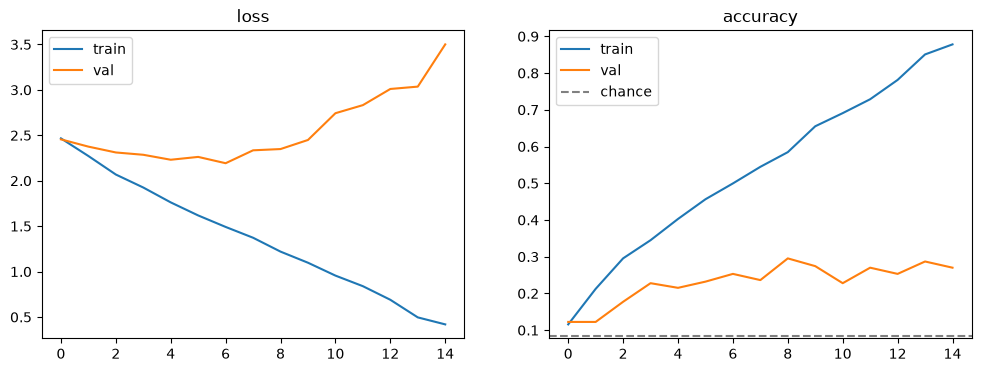

In [17]:
train_loss, val_loss, train_acc, val_acc = zip(*history)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_loss, label="train")
ax1.plot(val_loss, label="val")
ax1.set_title("loss")
ax1.legend()
ax2.plot(train_acc, label="train")
ax2.plot(val_acc, label="val")
ax2.axhline(1 / len(breeds), color="grey", linestyle="--", label="chance")
ax2.set_title("accuracy")
ax2.legend()

### What to look for
- Loss starts near `2.48`? Then the model starts out guessing, as it should.
- **Train accuracy keeps climbing while val stalls or val loss rises → overfitting**: the model memorises these ~950 images instead of learning breeds. That is the problem step 3 tackles.
- Note the best val accuracy in the log in `CLASSIFIER_PLAN.md`.